# Prototype 21 — Enriched Jev Inputs (Variants A + B)

**Follow-up to notebook 20.** Baseline result there:
- Jev-Choice: 60% agreement with Gemini top-3, **median confidence 0.37** (flat, near-random).
- Jev-Noul (composite): 40% agreement, top-score median 0.775.

**Hypothesis:** median confidence was flat because the criteria string
`"[id] Name — top:coat, bottom:pants"` under-specifies the discriminating
features. Jev is a closed-set decision model; give it structured signal on
the features that actually decide the answer (materials, colors, wear
context vs. weather; occasion tags vs. situation) and calibrated
confidence should rise.

**Two variants tested here** (both share the same fixture set + closet set
as nb20 so cached Gemini top-3 remains the ground truth):

- **Variant A — enriched Choice + independent Noul.** Same shape as nb20:
  one Choice question over all outfits, plus one Noul per outfit. Change:
  `state` becomes a structured JSON blob with typed weather/occasion
  context; `criteria` values become per-outfit JSON objects listing every
  item's category/subcategory/colors/material/wearContext.
- **Variant B — per-attribute Noul fan-out.** Instead of one composite
  Noul per outfit, fire 4 orthogonal Nouls (`weather_fit`,
  `occasion_fit`, `formality_fit`, `color_harmony`) per outfit in a
  single call. Aggregate outside as a weighted mean; rank by aggregate.

**Guardrails:**
- Token budget estimated before every call; if the 4× fan-out approaches
  Jev's 64k state+questions limit we chunk into two calls of half the
  outfits each.
- Total spend for this notebook capped at $0.05 (soft; the plan doc's
  per-call cost is ~$0.0001, so 10 fixtures × 3 calls ≈ $0.003 expected).

**Data / caveats:**
- Uses the same active user + same outfit set as nb20 (all outfits
  belonging to the top-item-count user). Baseline `20_gemini_raw.json` is
  read verbatim for Gemini top-3 ground truth — we do NOT re-run Gemini.
- Loader functions are copied from `build_notebook_20.py` unchanged.
- Jev endpoint remains `POST https://openrouter.ai/api/alpha/decisions`.


## 1. Setup — imports, env, paths


In [16]:
from __future__ import annotations

import json
import os
import sqlite3
import statistics
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

REPO_ROOT = Path.cwd().parent.parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Load .env if present (matches other notebooks' convention)
env_path = REPO_ROOT / ".env"
if env_path.exists():
    for line in env_path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith("#") or "=" not in line:
            continue
        k, v = line.split("=", 1)
        os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

CLOSET_DATA_DIR = Path(os.environ.get("CLOSET_DATA_DIR", str(Path.home() / ".closet")))
# nb20 read from ~/.closet/closet.db (default). If that doesn't exist, fall
# back to the repo-local .closet/closet.db (the dev DB used in this task).
CANDIDATE_DBS = [
    CLOSET_DATA_DIR / "closet.db",
    REPO_ROOT / ".closet" / "closet.db",
]
CLOSET_DB = next((p for p in CANDIDATE_DBS if p.exists()), CANDIDATE_DBS[0])

OUT_DIR = REPO_ROOT / "prototypes" / "outputs" / "21"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = REPO_ROOT / "prototypes" / "cache"
CACHE_DIR.mkdir(exist_ok=True)

print(f"CLOSET_DB:      {CLOSET_DB}  exists={CLOSET_DB.exists()}")
print(f"OUT_DIR:        {OUT_DIR}")
print(f"OPENROUTER_API_KEY set: {bool(os.environ.get('OPENROUTER_API_KEY'))}")


CLOSET_DB:      .closet/closet.db  exists=True
OUT_DIR:        prototypes/outputs/21
OPENROUTER_API_KEY set: True


## 2. Jev client — copied verbatim from nb20


In [18]:
import urllib.request
import urllib.error

JEV_MODEL = "typesafe/jev-1.13"
DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"


def call_jev_decisions(state, questions: dict, *, timeout_s: int = 60) -> dict:
    """POST to OpenRouter's decisions endpoint. Returns a dict with:
      {ok: bool, latency_s, model, answers, usage, error?}"""
    api_key = os.environ.get("OPENROUTER_API_KEY", "")
    if not api_key:
        return {"ok": False, "error": "OPENROUTER_API_KEY not set"}
    body = json.dumps({"model": JEV_MODEL, "state": state, "questions": questions}).encode()
    req = urllib.request.Request(
        DECISIONS_URL,
        data=body,
        method="POST",
        headers={"Authorization": f"Bearer {api_key}", "Content-Type": "application/json"},
    )
    t0 = time.perf_counter()
    try:
        with urllib.request.urlopen(req, timeout=timeout_s) as resp:
            payload = json.loads(resp.read())
        return {
            "ok": True,
            "latency_s": time.perf_counter() - t0,
            "model": payload.get("model"),
            "answers": payload.get("answers") or {},
            "usage": payload.get("usage") or {},
            "id": payload.get("id"),
            "provider": payload.get("provider"),
        }
    except urllib.error.HTTPError as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0,
                "error": f"HTTP {e.code}: {e.read()[:400].decode(errors='replace')}"}
    except Exception as e:
        return {"ok": False, "latency_s": time.perf_counter() - t0,
                "error": f"{type(e).__name__}: {e}"}


## 3. Data loaders — copied verbatim from nb20


In [20]:
def pick_active_user(db_path: Path) -> str | None:
    if not db_path.exists():
        return None
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    row = conn.execute(
        "SELECT user_id, COUNT(*) c FROM items GROUP BY user_id ORDER BY c DESC LIMIT 1"
    ).fetchone()
    conn.close()
    return row[0] if row else None


def fetch_closet_items(db_path: Path, user_id: str) -> list[dict]:
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    conn.row_factory = sqlite3.Row
    rows = conn.execute(
        """
        SELECT id, category, subcategory, colors, brand, material, season,
               occasion, tags, ai_description, image_uri, wear_context
        FROM items
        WHERE user_id = ?
        ORDER BY id
        """,
        (user_id,),
    ).fetchall()
    conn.close()
    out = []
    for r in rows:
        d = dict(r)
        for jf in ("colors", "season", "occasion", "tags"):
            try:
                d[jf] = json.loads(d[jf]) if d[jf] else []
            except (json.JSONDecodeError, TypeError):
                d[jf] = []
        out.append(d)
    return out


def fetch_closet_outfits(db_path: Path, user_id: str) -> list[dict]:
    conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)
    conn.row_factory = sqlite3.Row
    rows = conn.execute(
        """
        SELECT id, name, item_ids, occasion, season, notes
        FROM outfits
        WHERE user_id = ?
        ORDER BY id
        """,
        (user_id,),
    ).fetchall()
    conn.close()
    out = []
    for r in rows:
        d = dict(r)
        for jf in ("item_ids", "season"):
            try:
                d[jf] = json.loads(d[jf]) if d[jf] else []
            except (json.JSONDecodeError, TypeError):
                d[jf] = []
        out.append(d)
    return out


ACTIVE_USER = pick_active_user(CLOSET_DB)
print(f"Active user (most items): {ACTIVE_USER}")

items = fetch_closet_items(CLOSET_DB, ACTIVE_USER) if ACTIVE_USER else []
outfits = fetch_closet_outfits(CLOSET_DB, ACTIVE_USER) if ACTIVE_USER else []
items_by_id = {it["id"]: it for it in items}

print(f"Items:   {len(items)}")
print(f"Outfits: {len(outfits)}")


Active user (most items): self
Items:   41
Outfits: 32


## 4. Fixtures — copied verbatim from nb20


In [22]:
FIXTURES = [
    {
        "id": "rainy_work_morning",
        "weather": {"temperature": 13, "condition": "Rainy", "precipitation": 5.2, "windSpeed": 15},
        "occasion": "office",
        "theme": None,
        "timeOfDay": "morning",
        "dayOfWeek": "Tuesday",
    },
    {
        "id": "hot_brunch_weekend",
        "weather": {"temperature": 32, "condition": "Sunny", "precipitation": 0, "windSpeed": 5},
        "occasion": "brunch",
        "theme": "weekend, want to feel breezy",
        "timeOfDay": "midday",
        "dayOfWeek": "Saturday",
    },
    {
        "id": "cold_formal_interview",
        "weather": {"temperature": -2, "condition": "Snow", "precipitation": 1, "windSpeed": 20},
        "occasion": "job interview",
        "theme": None,
        "timeOfDay": "morning",
        "dayOfWeek": "Monday",
    },
    {
        "id": "warm_casual_errands",
        "weather": {"temperature": 22, "condition": "Cloudy", "precipitation": 0, "windSpeed": 8},
        "occasion": "running errands",
        "theme": None,
        "timeOfDay": "afternoon",
        "dayOfWeek": "Saturday",
    },
    {
        "id": "mild_evening_date",
        "weather": {"temperature": 17, "condition": "Clear", "precipitation": 0, "windSpeed": 3},
        "occasion": "dinner date",
        "theme": "want to look put-together but not overdressed",
        "timeOfDay": "evening",
        "dayOfWeek": "Friday",
    },
    {
        "id": "cold_wfh",
        "weather": {"temperature": 4, "condition": "Cloudy", "precipitation": 0, "windSpeed": 12},
        "occasion": "working from home",
        "theme": "comfortable but presentable for video calls",
        "timeOfDay": "morning",
        "dayOfWeek": "Wednesday",
    },
    {
        "id": "humid_wedding",
        "weather": {"temperature": 28, "condition": "Humid", "precipitation": 0, "windSpeed": 4},
        "occasion": "outdoor wedding",
        "theme": None,
        "timeOfDay": "afternoon",
        "dayOfWeek": "Sunday",
    },
    {
        "id": "windy_outdoor_walk",
        "weather": {"temperature": 10, "condition": "Windy", "precipitation": 0, "windSpeed": 35},
        "occasion": "long walk in the park",
        "theme": None,
        "timeOfDay": "midday",
        "dayOfWeek": "Sunday",
    },
    {
        "id": "cool_workout",
        "weather": {"temperature": 15, "condition": "Clear", "precipitation": 0, "windSpeed": 6},
        "occasion": "outdoor run",
        "theme": None,
        "timeOfDay": "morning",
        "dayOfWeek": "Thursday",
    },
    {
        "id": "cold_evening_out",
        "weather": {"temperature": 6, "condition": "Clear", "precipitation": 0, "windSpeed": 10},
        "occasion": "concert",
        "theme": "want to stand out a bit",
        "timeOfDay": "evening",
        "dayOfWeek": "Friday",
    },
]

pd.DataFrame(FIXTURES)


,id,weather,occasion,theme,timeOfDay,dayOfWeek
0,rainy_work_morning,"{'temperature': 13, 'condition': 'Rainy', 'pre...",office,NaN,morning,Tuesday
1,hot_brunch_weekend,"{'temperature': 32, 'condition': 'Sunny', 'pre...",brunch,"weekend, want to feel breezy",midday,Saturday
2,cold_formal_interview,"{'temperature': -2, 'condition': 'Snow', 'prec...",job interview,NaN,morning,Monday
3,warm_casual_errands,"{'temperature': 22, 'condition': 'Cloudy', 'pr...",running errands,NaN,afternoon,Saturday
4,mild_evening_date,"{'temperature': 17, 'condition': 'Clear', 'pre...",dinner date,want to look put-together but not overdressed,evening,Friday
5,cold_wfh,"{'temperature': 4, 'condition': 'Cloudy', 'pre...",working from home,comfortable but presentable for video calls,morning,Wednesday
6,humid_wedding,"{'temperature': 28, 'condition': 'Humid', 'pre...",outdoor wedding,NaN,afternoon,Sunday
7,windy_outdoor_walk,"{'temperature': 10, 'condition': 'Windy', 'pre...",long walk in the park,NaN,midday,Sunday
8,cool_workout,"{'temperature': 15, 'condition': 'Clear', 'pre...",outdoor run,NaN,morning,Thursday
9,cold_evening_out,"{'temperature': 6, 'condition': 'Clear', 'prec...",concert,want to stand out a bit,evening,Friday


## 5. Enriched state + criteria builders

`fixture_state_enriched` gives Jev a **typed** view of the situation — same
weather + occasion + time fields as nb20 but explicitly labelled.

`outfit_criteria_json` returns, per outfit, a JSON object with:
- `name`, `occasion` (from outfit metadata)
- `items[]`: each item's `category`, `subcategory`, `colors[:3]`,
  `material`, `wearContext`.

Passing JSON dicts as `criteria` values (rather than strings) is what
gives Jev structured signal per option. Keep item metadata OUT of `state`
— it belongs in criteria to keep state bounded (context-rot guardrail).


In [24]:
def fixture_state_enriched(fx: dict) -> dict:
    w = fx["weather"]
    return {
        "weather": {
            "temperature_c": w["temperature"],
            "condition": w["condition"],
            "precipitation_mm": w.get("precipitation", 0),
            "wind_kmh": w.get("windSpeed", 0),
        },
        "occasion": fx.get("occasion"),
        "time_of_day": fx.get("timeOfDay"),
        "day_of_week": fx.get("dayOfWeek"),
        "theme": fx.get("theme"),
    }


def outfit_criteria_json(outfits: list[dict], by_id: dict[str, dict]) -> dict[str, dict]:
    """Per-outfit JSON blob for the Choice criteria (Variant A shape)."""
    out: dict[str, dict] = {}
    for o in outfits:
        items_repr = []
        for iid in o.get("item_ids", []):
            it = by_id.get(iid)
            if not it:
                continue
            entry = {
                "category": it.get("category") or "?",
            }
            if it.get("subcategory"):
                entry["subcategory"] = it["subcategory"]
            if it.get("colors"):
                entry["colors"] = it["colors"][:3]
            if it.get("material"):
                entry["material"] = it["material"]
            wc = it.get("wear_context")
            if wc:
                entry["wearContext"] = wc
            items_repr.append(entry)
        out[o["id"]] = {
            "name": o.get("name") or "Unnamed",
            "occasion": o.get("occasion") or None,
            "items": items_repr,
        }
    return out


def outfit_criteria_strings(outfits: list[dict], by_id: dict[str, dict]) -> dict[str, str]:
    """nb20-equivalent collapsed-string criteria, for token-diff sanity check."""
    out = {}
    for o in outfits:
        item_descs = []
        for iid in o.get("item_ids", []):
            it = by_id.get(iid)
            if not it:
                continue
            desc = it.get("category", "?")
            if it.get("subcategory"):
                desc += f":{it['subcategory']}"
            if it.get("colors"):
                desc += f" ({'/'.join(it['colors'][:2])})"
            item_descs.append(desc)
        name = o.get("name") or "Unnamed"
        out[o["id"]] = f"{name} — {', '.join(item_descs) or '(empty)'}"
    return out


def rough_tokens(obj) -> int:
    """Rough token estimate: chars / 4. Good enough to catch runaway prompts."""
    return max(1, len(json.dumps(obj, default=str)) // 4)


if outfits:
    enr = outfit_criteria_json(outfits, items_by_id)
    plain = outfit_criteria_strings(outfits, items_by_id)
    print(f"Outfits in scope: {len(outfits)}")
    print(f"Est tokens — enriched criteria dict:  ~{rough_tokens(enr):>6}")
    print(f"Est tokens — plain-string criteria:   ~{rough_tokens(plain):>6}")
    print(f"Ratio (enriched / plain): {rough_tokens(enr) / rough_tokens(plain):.2f}x")
    print()
    sample_id = next(iter(enr))
    print(f"Sample enriched criterion for {sample_id}:")
    print(json.dumps(enr[sample_id], indent=2)[:600])


Outfits in scope: 32
Est tokens — enriched criteria dict:  ~  3125
Est tokens — plain-string criteria:   ~  1325
Ratio (enriched / plain): 2.36x

Sample enriched criterion for 3mjI4uL_liCuGuJMvrxOH:
{
  "name": "The Eccentric Urbanite",
  "occasion": "casual",
  "items": [
    {
      "category": "tops",
      "subcategory": "button-down shirt",
      "colors": [
        "purple",
        "white",
        "black"
      ]
    },
    {
      "category": "bottoms",
      "subcategory": "sweatpants",
      "colors": [
        "yellow"
      ]
    },
    {
      "category": "outerwear",
      "subcategory": "trench coat",
      "colors": [
        "tan"
      ]
    },
    {
      "category": "accessories",
      "subcategory": "scarf",
      "colors": [
        "off-white",
        "maroon"
  


## 6. Variant A — enriched Choice + independent Nouls

Same call shape as nb20's §7 — one Choice question + one Noul per outfit
— but every criterion is a structured JSON blob.


In [26]:
def call_va_choice(fx: dict, outfits: list[dict], by_id: dict[str, dict]) -> dict:
    criteria = outfit_criteria_json(outfits, by_id)
    state = fixture_state_enriched(fx)
    result = call_jev_decisions(state, {
        "best": {
            "type": "choice",
            "instructions": (
                "Pick the single best saved outfit for the given weather + "
                "occasion + time context. Consider material vs temperature "
                "and wet weather, color/formality vs the occasion, and "
                "wearContext hints on individual items."
            ),
            "criteria": criteria,
        },
    })
    ans = (result.get("answers") or {}).get("best") or {}
    usage = result.get("usage") or {}
    return {
        "fixture_id": fx["id"],
        "provider": "va-choice",
        "model": result.get("model"),
        "ok": result.get("ok"),
        "error": result.get("error"),
        "top_id": ans.get("choice"),
        "confidence": ans.get("confidence"),
        "probabilities": ans.get("probabilities") or {},
        "latency_s": result.get("latency_s"),
        "tokens_in": usage.get("input_tokens", 0),
        "tokens_out": usage.get("output_tokens", 0),
        "cost_usd": float(usage.get("cost", 0.0)),
    }


def call_va_noul(fx: dict, outfits: list[dict], by_id: dict[str, dict]) -> dict:
    state = fixture_state_enriched(fx)
    criteria_json = outfit_criteria_json(outfits, by_id)
    # Encode the outfit JSON right into the noul instructions so each
    # question sees its own structured payload (Jev's noul type has no
    # `criteria` slot the way choice does).
    questions = {}
    for o in outfits:
        oj = criteria_json.get(o["id"])
        if not oj:
            continue
        questions[f"q_{o['id']}"] = {
            "type": "noul",
            "instructions": (
                "Is this outfit a good pick for the given context? "
                f"Outfit JSON: {json.dumps(oj)}"
            ),
        }
    result = call_jev_decisions(state, questions)
    answers = result.get("answers") or {}
    usage = result.get("usage") or {}

    ranked = []
    for o in outfits:
        a = answers.get(f"q_{o['id']}") or {}
        nv = a.get("noul")
        if nv is not None:
            ranked.append((o["id"], float(nv)))
    ranked.sort(key=lambda kv: kv[1], reverse=True)

    return {
        "fixture_id": fx["id"],
        "provider": "va-noul",
        "model": result.get("model"),
        "ok": result.get("ok"),
        "error": result.get("error"),
        "ranked_ids": [oid for oid, _ in ranked],
        "top_id": ranked[0][0] if ranked else None,
        "top_score": ranked[0][1] if ranked else None,
        "all_scores": {oid: s for oid, s in ranked},
        "latency_s": result.get("latency_s"),
        "tokens_in": usage.get("input_tokens", 0),
        "tokens_out": usage.get("output_tokens", 0),
        "cost_usd": float(usage.get("cost", 0.0)),
    }


if len(outfits) < 2 or not os.environ.get("OPENROUTER_API_KEY"):
    print("SKIP Variant A: insufficient outfits or no OPENROUTER_API_KEY.")
    va_choice_results, va_noul_results = [], []
else:
    va_choice_results, va_noul_results = [], []
    for fx in FIXTURES:
        rc = call_va_choice(fx, outfits, items_by_id)
        va_choice_results.append(rc)
        print(f"[va-c] {fx['id']:32s}  top={rc['top_id']}  conf={rc['confidence']}  lat={rc['latency_s']:.2f}s  cost=${rc['cost_usd']:.6f}  err={rc['error']}")
        rn = call_va_noul(fx, outfits, items_by_id)
        va_noul_results.append(rn)
        print(f"[va-n] {fx['id']:32s}  top={rn['top_id']}  score={rn['top_score']}  lat={rn['latency_s']:.2f}s  cost=${rn['cost_usd']:.6f}  err={rn['error']}")

(CACHE_DIR / "21_va_choice_raw.json").write_text(json.dumps(va_choice_results, indent=2, default=str))
(CACHE_DIR / "21_va_noul_raw.json").write_text(json.dumps(va_noul_results, indent=2, default=str))


[va-c] rainy_work_morning                top=xhmrEFiS46n4byiproYXL  conf=0.42  lat=0.42s  cost=$0.000255  err=None
[va-n] rainy_work_morning                top=xhmrEFiS46n4byiproYXL  score=0.86  lat=0.27s  cost=$0.000193  err=None
[va-c] hot_brunch_weekend                top=yc9yH6OwdG6XqCv3kb1W3  conf=0.42  lat=0.30s  cost=$0.000255  err=None
[va-n] hot_brunch_weekend                top=6eZ3qmugmy2RpIkK_WqZL  score=0.77  lat=0.38s  cost=$0.000194  err=None
[va-c] cold_formal_interview             top=xhmrEFiS46n4byiproYXL  conf=0.54  lat=0.92s  cost=$0.000255  err=None
[va-n] cold_formal_interview             top=xhmrEFiS46n4byiproYXL  score=0.75  lat=6.05s  cost=$0.000193  err=None
[va-c] warm_casual_errands               top=yc9yH6OwdG6XqCv3kb1W3  conf=0.52  lat=0.42s  cost=$0.000255  err=None
[va-n] warm_casual_errands               top=yc9yH6OwdG6XqCv3kb1W3  score=0.82  lat=1.10s  cost=$0.000193  err=None
[va-c] mild_evening_date                 top=Oi3-nbxDCVc8QjTCGb8xf  conf=0.4

25508

## 7. Variant B — per-attribute Noul fan-out

For each outfit `o`, we fire 4 Nouls:
- `weather_fit`  — appropriate for the weather?
- `occasion_fit` — appropriate for the occasion?
- `formality_fit` — formality matches the situation?
- `color_harmony` — do the colors within this outfit work together?

Aggregate outside via weighted mean:
- weather_fit=0.35, occasion_fit=0.35, formality_fit=0.20, color_harmony=0.10

**Chunking:** 4 questions × N outfits. If N × 4 tokens push past ~30k of
the 64k combined-context ceiling for state+questions, we split into two
Jev calls (halves of the outfit list) and merge answers. Rough token
estimate below decides.

Attribute-level confidence distributions are inspected separately — they
should be **higher** than the composite Noul from nb20 because each
question asks a narrower thing.


In [28]:
ATTR_WEIGHTS = {
    "weather_fit": 0.35,
    "occasion_fit": 0.35,
    "formality_fit": 0.20,
    "color_harmony": 0.10,
}


def _attr_instructions(oj: dict, attr: str) -> str:
    js = json.dumps(oj)
    if attr == "weather_fit":
        return (
            "Considering only the weather (temperature, precipitation, wind), "
            f"is this outfit appropriate? Outfit JSON: {js}"
        )
    if attr == "occasion_fit":
        return (
            "Considering only the occasion, is this outfit appropriate? "
            f"Outfit JSON: {js}"
        )
    if attr == "formality_fit":
        return (
            "Does this outfit's formality level match the situation "
            f"(occasion + time of day)? Outfit JSON: {js}"
        )
    if attr == "color_harmony":
        return (
            "Do the colors within this outfit work together? "
            f"Outfit JSON: {js}"
        )
    raise ValueError(attr)


def build_vb_questions(outfits: list[dict], criteria_json: dict[str, dict]) -> dict:
    questions = {}
    for o in outfits:
        oj = criteria_json.get(o["id"])
        if not oj:
            continue
        for attr in ATTR_WEIGHTS:
            questions[f"q_{o['id']}__{attr}"] = {
                "type": "noul",
                "instructions": _attr_instructions(oj, attr),
            }
    return questions


def _chunk(seq, n):
    for i in range(0, len(seq), n):
        yield seq[i : i + n]


def call_vb(fx: dict, outfits: list[dict], by_id: dict[str, dict]) -> dict:
    state = fixture_state_enriched(fx)
    criteria_json = outfit_criteria_json(outfits, by_id)

    # Token estimate — if it'd blow past 30k combined, chunk in halves.
    full_qs = build_vb_questions(outfits, criteria_json)
    est = rough_tokens({"state": state, "questions": full_qs})
    chunk_size = len(outfits) if est < 30000 else max(1, len(outfits) // 2)
    chunks = list(_chunk(outfits, chunk_size))

    merged_answers: dict = {}
    total_latency = 0.0
    total_cost = 0.0
    total_tokens_in = 0
    total_tokens_out = 0
    first_error = None
    model_seen = None

    for chunk in chunks:
        qs = build_vb_questions(chunk, criteria_json)
        result = call_jev_decisions(state, qs)
        model_seen = model_seen or result.get("model")
        total_latency += float(result.get("latency_s") or 0.0)
        usage = result.get("usage") or {}
        total_cost += float(usage.get("cost", 0.0))
        total_tokens_in += int(usage.get("input_tokens", 0) or 0)
        total_tokens_out += int(usage.get("output_tokens", 0) or 0)
        if not result.get("ok") and first_error is None:
            first_error = result.get("error")
        merged_answers.update(result.get("answers") or {})

    # Aggregate per outfit
    per_outfit: list[dict] = []
    for o in outfits:
        attrs: dict[str, float] = {}
        for attr in ATTR_WEIGHTS:
            a = merged_answers.get(f"q_{o['id']}__{attr}") or {}
            nv = a.get("noul")
            if nv is None:
                continue
            attrs[attr] = float(nv)
        if not attrs:
            continue
        # Weighted mean, only over attributes we got back.
        total_w = sum(ATTR_WEIGHTS[a] for a in attrs)
        agg = sum(ATTR_WEIGHTS[a] * v for a, v in attrs.items()) / total_w if total_w else None
        per_outfit.append({"outfit_id": o["id"], "aggregate": agg, "attrs": attrs})

    per_outfit.sort(key=lambda r: (r["aggregate"] is None, -(r["aggregate"] or 0.0)))

    return {
        "fixture_id": fx["id"],
        "provider": "vb-fanout",
        "model": model_seen,
        "ok": first_error is None,
        "error": first_error,
        "chunks": len(chunks),
        "est_tokens": est,
        "ranked": per_outfit,
        "top_id": per_outfit[0]["outfit_id"] if per_outfit else None,
        "top_score": per_outfit[0]["aggregate"] if per_outfit else None,
        "latency_s": total_latency,
        "tokens_in": total_tokens_in,
        "tokens_out": total_tokens_out,
        "cost_usd": total_cost,
    }


if len(outfits) < 2 or not os.environ.get("OPENROUTER_API_KEY"):
    print("SKIP Variant B: insufficient outfits or no OPENROUTER_API_KEY.")
    vb_results = []
else:
    vb_results = []
    for fx in FIXTURES:
        r = call_vb(fx, outfits, items_by_id)
        vb_results.append(r)
        print(f"[vb  ] {fx['id']:32s}  top={r['top_id']}  score={r['top_score']}  chunks={r['chunks']}  est_tok={r['est_tokens']}  lat={r['latency_s']:.2f}s  cost=${r['cost_usd']:.6f}  err={r['error']}")

(CACHE_DIR / "21_vb_raw.json").write_text(json.dumps(vb_results, indent=2, default=str))


[vb  ] rainy_work_morning                top=xhmrEFiS46n4byiproYXL  score=0.8635  chunks=1  est_tok=18800  lat=0.67s  cost=$0.000741  err=None
[vb  ] hot_brunch_weekend                top=yc9yH6OwdG6XqCv3kb1W3  score=0.7404999999999999  chunks=1  est_tok=18805  lat=0.53s  cost=$0.000742  err=None
[vb  ] cold_formal_interview             top=xhmrEFiS46n4byiproYXL  score=0.698  chunks=1  est_tok=18800  lat=0.41s  cost=$0.000741  err=None
[vb  ] warm_casual_errands               top=yc9yH6OwdG6XqCv3kb1W3  score=0.8455  chunks=1  est_tok=18802  lat=0.45s  cost=$0.000741  err=None
[vb  ] mild_evening_date                 top=Oi3-nbxDCVc8QjTCGb8xf  score=0.5844999999999999  chunks=1  est_tok=18811  lat=0.69s  cost=$0.000742  err=None
[vb  ] cold_wfh                          top=sIIlkYdOoMoax7L7sNub4  score=0.7334999999999999  chunks=1  est_tok=18813  lat=0.41s  cost=$0.000742  err=None
[vb  ] humid_wedding                     top=6eZ3qmugmy2RpIkK_WqZL  score=0.43  chunks=1  est_tok=18801  la

84399

## 8. Comparison table — v1 (nb20 cache) vs v2a vs v2b

Loads the cached Gemini top-3 + nb20 Jev-Choice confidences, builds a
per-variant summary, writes CSV to `outputs/21/21_metrics.csv`.


In [30]:
NB20_GEMINI = json.loads((CACHE_DIR / "20_gemini_raw.json").read_text())
NB20_JEV_CHOICE = json.loads((CACHE_DIR / "20_jev_choice_raw.json").read_text())
NB20_JEV_NOUL = json.loads((CACHE_DIR / "20_jev_noul_raw.json").read_text())

gemini_by_fx = {r["fixture_id"]: r for r in NB20_GEMINI}
v1_choice_by_fx = {r["fixture_id"]: r for r in NB20_JEV_CHOICE}
v1_noul_by_fx = {r["fixture_id"]: r for r in NB20_JEV_NOUL}

va_c_by_fx = {r["fixture_id"]: r for r in va_choice_results}
va_n_by_fx = {r["fixture_id"]: r for r in va_noul_results}
vb_by_fx = {r["fixture_id"]: r for r in vb_results}


def _top3(g: dict) -> list[str]:
    return list(g.get("top_ids") or [])[:3]


rows = []
for fx in FIXTURES:
    fid = fx["id"]
    g_top3 = _top3(gemini_by_fx.get(fid, {}))
    v1c = v1_choice_by_fx.get(fid, {})
    v1n = v1_noul_by_fx.get(fid, {})
    vac = va_c_by_fx.get(fid, {})
    van = va_n_by_fx.get(fid, {})
    vb = vb_by_fx.get(fid, {})

    def _agree(tid):
        return (tid in g_top3) if (g_top3 and tid) else None

    rows.append({
        "fixture_id": fid,
        "gemini_top3": ",".join(g_top3),
        # v1 (nb20)
        "v1_choice_top": v1c.get("top_id"),
        "v1_choice_conf": v1c.get("confidence"),
        "v1_choice_agree": _agree(v1c.get("top_id")),
        "v1_choice_lat_s": v1c.get("latency_s"),
        "v1_choice_cost": v1c.get("cost_usd"),
        "v1_noul_top": v1n.get("top_id"),
        "v1_noul_top_score": v1n.get("top_score"),
        "v1_noul_agree": _agree(v1n.get("top_id")),
        "v1_noul_lat_s": v1n.get("latency_s"),
        "v1_noul_cost": v1n.get("cost_usd"),
        # v2a — enriched choice + noul
        "va_choice_top": vac.get("top_id"),
        "va_choice_conf": vac.get("confidence"),
        "va_choice_agree": _agree(vac.get("top_id")),
        "va_choice_lat_s": vac.get("latency_s"),
        "va_choice_cost": vac.get("cost_usd"),
        "va_noul_top": van.get("top_id"),
        "va_noul_top_score": van.get("top_score"),
        "va_noul_agree": _agree(van.get("top_id")),
        "va_noul_lat_s": van.get("latency_s"),
        "va_noul_cost": van.get("cost_usd"),
        # v2b — per-attribute fan-out
        "vb_top": vb.get("top_id"),
        "vb_top_score": vb.get("top_score"),
        "vb_agree": _agree(vb.get("top_id")),
        "vb_lat_s": vb.get("latency_s"),
        "vb_cost": vb.get("cost_usd"),
        "vb_chunks": vb.get("chunks"),
        "vb_est_tokens": vb.get("est_tokens"),
    })

metrics_df = pd.DataFrame(rows)
csv_path = OUT_DIR / "21_metrics.csv"
metrics_df.to_csv(csv_path, index=False)
print(f"Wrote {csv_path}")
metrics_df


Wrote prototypes/outputs/21/21_metrics.csv


,fixture_id,gemini_top3,v1_choice_top,v1_choice_conf,v1_choice_agree,v1_choice_lat_s,v1_choice_cost,v1_noul_top,v1_noul_top_score,v1_noul_agree,...,va_noul_agree,va_noul_lat_s,va_noul_cost,vb_top,vb_top_score,vb_agree,vb_lat_s,vb_cost,vb_chunks,vb_est_tokens
0,rainy_work_morning,"4i0x-7A3qEedcol_EX40e,eaRrq_OeK-pHLT_LFcxia,_D...",xhmrEFiS46n4byiproYXL,0.46,False,0.317734,0.000102,xhmrEFiS46n4byiproYXL,0.85,False,...,False,0.271568,0.000193,xhmrEFiS46n4byiproYXL,0.8635,False,0.669648,0.000741,1,18800
1,hot_brunch_weekend,"6eZ3qmugmy2RpIkK_WqZL,yc9yH6OwdG6XqCv3kb1W3,zE...",6eZ3qmugmy2RpIkK_WqZL,0.57,True,0.403065,0.000102,6eZ3qmugmy2RpIkK_WqZL,0.85,True,...,True,0.378925,0.000194,yc9yH6OwdG6XqCv3kb1W3,0.7405,True,0.529114,0.000742,1,18805
2,cold_formal_interview,"eaRrq_OeK-pHLT_LFcxia,4i0x-7A3qEedcol_EX40e,_D...",eaRrq_OeK-pHLT_LFcxia,0.39,True,0.237458,0.000102,xhmrEFiS46n4byiproYXL,0.76,False,...,False,6.047151,0.000193,xhmrEFiS46n4byiproYXL,0.6980,False,0.406890,0.000741,1,18800
3,warm_casual_errands,"AtFFqYhsGkLuPfVLBwLml,BOwXAKOOfDD6qEsBB-O00,3t...",6eZ3qmugmy2RpIkK_WqZL,0.22,False,0.412456,0.000102,yc9yH6OwdG6XqCv3kb1W3,0.85,False,...,False,1.102893,0.000193,yc9yH6OwdG6XqCv3kb1W3,0.8455,False,0.450725,0.000741,1,18802
4,mild_evening_date,"Oi3-nbxDCVc8QjTCGb8xf,UHf892G4nj1d0-IqUCbRO,u_...",Oi3-nbxDCVc8QjTCGb8xf,0.37,True,0.263362,0.000103,UHf892G4nj1d0-IqUCbRO,0.71,True,...,True,1.196200,0.000194,Oi3-nbxDCVc8QjTCGb8xf,0.5845,True,0.687588,0.000742,1,18811
5,cold_wfh,"3mjI4uL_liCuGuJMvrxOH,9j7e9F9apglkh3Aery96O,UH...",UHf892G4nj1d0-IqUCbRO,0.45,True,0.229796,0.000103,UHf892G4nj1d0-IqUCbRO,0.84,True,...,True,0.237806,0.000194,sIIlkYdOoMoax7L7sNub4,0.7335,False,0.407305,0.000742,1,18813
6,humid_wedding,"SMqx54IhUJo5FXC3S1gRl,FbqWbYwov8KOJpNSvsIl9,6R...",SMqx54IhUJo5FXC3S1gRl,0.31,True,0.269709,0.000102,PnymfGQkkYf7djgfa1L_9,0.32,False,...,True,0.289613,0.000193,6eZ3qmugmy2RpIkK_WqZL,0.4300,False,0.470609,0.000741,1,18801
7,windy_outdoor_walk,"3mjI4uL_liCuGuJMvrxOH,Nn2AG8F-cJ_4-6lC_lMk,9j7...",AtFFqYhsGkLuPfVLBwLml,0.28,False,0.360286,0.000102,AtFFqYhsGkLuPfVLBwLml,0.79,False,...,False,0.236882,0.000193,AtFFqYhsGkLuPfVLBwLml,0.7830,False,0.599515,0.000741,1,18802
8,cool_workout,"6eZ3qmugmy2RpIkK_WqZL,yc9yH6OwdG6XqCv3kb1W3,3t...",yc9yH6OwdG6XqCv3kb1W3,0.37,True,0.309614,0.000102,6eZ3qmugmy2RpIkK_WqZL,0.55,True,...,True,0.286902,0.000193,6eZ3qmugmy2RpIkK_WqZL,0.7130,True,0.482747,0.000741,1,18800
9,cold_evening_out,"3mjI4uL_liCuGuJMvrxOH,jjnTreTimUK_K2nfmyvu3,Nn...",BOwXAKOOfDD6qEsBB-O00,0.23,False,0.205928,0.000102,BOwXAKOOfDD6qEsBB-O00,0.65,False,...,False,0.768248,0.000193,BOwXAKOOfDD6qEsBB-O00,0.6815,False,0.409397,0.000741,1,18804


In [31]:
def _series_median(s):
    s = s.dropna().astype(float)
    return float(s.median()) if len(s) else float("nan")


def _agree_pct(s):
    s = s.dropna()
    return float(s.mean()) if len(s) else float("nan")


summary = pd.DataFrame([
    {
        "variant": "v1 (nb20) Choice",
        "median_conf_or_topscore": _series_median(metrics_df["v1_choice_conf"]),
        "top1_agreement": _agree_pct(metrics_df["v1_choice_agree"]),
        "median_latency_s": _series_median(metrics_df["v1_choice_lat_s"]),
        "total_cost_usd": float(metrics_df["v1_choice_cost"].dropna().sum()),
    },
    {
        "variant": "v1 (nb20) Noul (composite)",
        "median_conf_or_topscore": _series_median(metrics_df["v1_noul_top_score"]),
        "top1_agreement": _agree_pct(metrics_df["v1_noul_agree"]),
        "median_latency_s": _series_median(metrics_df["v1_noul_lat_s"]),
        "total_cost_usd": float(metrics_df["v1_noul_cost"].dropna().sum()),
    },
    {
        "variant": "v2a enriched Choice",
        "median_conf_or_topscore": _series_median(metrics_df["va_choice_conf"]),
        "top1_agreement": _agree_pct(metrics_df["va_choice_agree"]),
        "median_latency_s": _series_median(metrics_df["va_choice_lat_s"]),
        "total_cost_usd": float(metrics_df["va_choice_cost"].dropna().sum()),
    },
    {
        "variant": "v2a enriched Noul",
        "median_conf_or_topscore": _series_median(metrics_df["va_noul_top_score"]),
        "top1_agreement": _agree_pct(metrics_df["va_noul_agree"]),
        "median_latency_s": _series_median(metrics_df["va_noul_lat_s"]),
        "total_cost_usd": float(metrics_df["va_noul_cost"].dropna().sum()),
    },
    {
        "variant": "v2b per-attr aggregate",
        "median_conf_or_topscore": _series_median(metrics_df["vb_top_score"]),
        "top1_agreement": _agree_pct(metrics_df["vb_agree"]),
        "median_latency_s": _series_median(metrics_df["vb_lat_s"]),
        "total_cost_usd": float(metrics_df["vb_cost"].dropna().sum()),
    },
])
summary_path = OUT_DIR / "21_summary.csv"
summary.to_csv(summary_path, index=False)
print(summary.to_string(index=False))
print(f"\nWrote {summary_path}")


                   variant  median_conf_or_topscore  top1_agreement  median_latency_s  total_cost_usd
          v1 (nb20) Choice                  0.37000             0.6          0.289661        0.001022
v1 (nb20) Noul (composite)                  0.77500             0.4          0.312911        0.000912
       v2a enriched Choice                  0.43000             0.4          0.355178        0.002551
         v2a enriched Noul                  0.74500             0.5          0.334269        0.001933
    v2b per-attr aggregate                  0.72325             0.3          0.476678        0.007414

Wrote prototypes/outputs/21/21_summary.csv


## 9. Chart — per-variant confidence + agreement


/var/folders/75/kdg1_qkj6wn1fpzpfk1h566r0000gn/T/ipykernel_67305/2888295956.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data, labels=labels, showmeans=True)


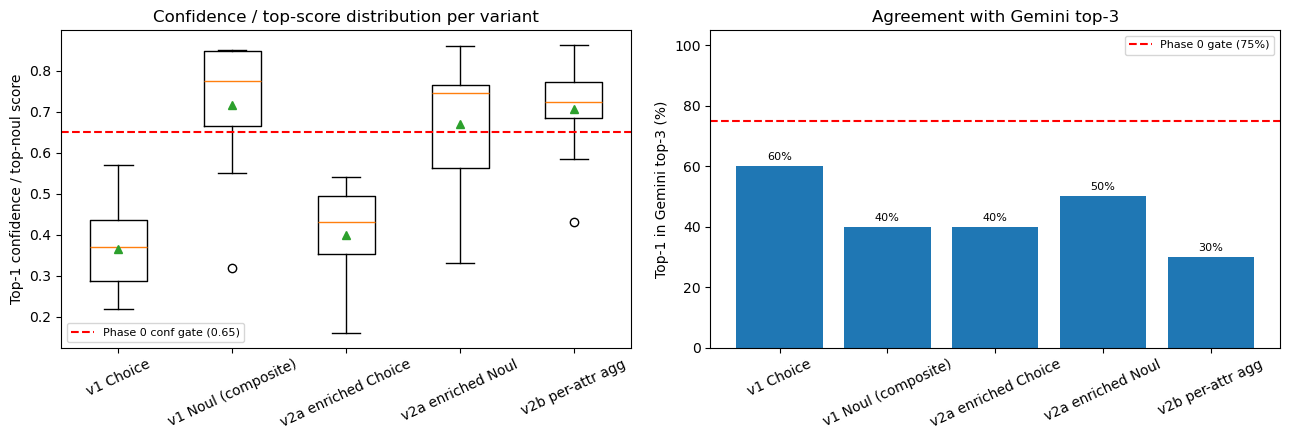

Saved chart to prototypes/outputs/21/21_summary.png


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Distribution of the "primary confidence-like number" per variant
series = {
    "v1 Choice": metrics_df["v1_choice_conf"].dropna().astype(float),
    "v1 Noul (composite)": metrics_df["v1_noul_top_score"].dropna().astype(float),
    "v2a enriched Choice": metrics_df["va_choice_conf"].dropna().astype(float),
    "v2a enriched Noul": metrics_df["va_noul_top_score"].dropna().astype(float),
    "v2b per-attr agg": metrics_df["vb_top_score"].dropna().astype(float),
}
labels = list(series.keys())
data = [list(series[k]) for k in labels]
axes[0].boxplot(data, labels=labels, showmeans=True)
axes[0].axhline(0.65, color="red", linestyle="--", label="Phase 0 conf gate (0.65)")
axes[0].set_ylabel("Top-1 confidence / top-noul score")
axes[0].set_title("Confidence / top-score distribution per variant")
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(fontsize=8)

# Bar of agreement
agreements = {
    "v1 Choice": _agree_pct(metrics_df["v1_choice_agree"]),
    "v1 Noul (composite)": _agree_pct(metrics_df["v1_noul_agree"]),
    "v2a enriched Choice": _agree_pct(metrics_df["va_choice_agree"]),
    "v2a enriched Noul": _agree_pct(metrics_df["va_noul_agree"]),
    "v2b per-attr agg": _agree_pct(metrics_df["vb_agree"]),
}
bars = axes[1].bar(list(agreements.keys()), [v * 100 for v in agreements.values()])
axes[1].axhline(75, color="red", linestyle="--", label="Phase 0 gate (75%)")
axes[1].set_ylabel("Top-1 in Gemini top-3 (%)")
axes[1].set_ylim(0, 105)
axes[1].set_title("Agreement with Gemini top-3")
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend(fontsize=8)
for bar, val in zip(bars, agreements.values()):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2,
                 f"{val:.0%}", ha="center", fontsize=8)

plt.tight_layout()
png_path = OUT_DIR / "21_summary.png"
plt.savefig(png_path, dpi=100)
plt.show()
print(f"Saved chart to {png_path}")


## 10. Per-attribute confidence — Variant B diagnostic

Compare the confidence distribution *inside* each per-attribute Noul.
Narrower questions should yield higher-confidence answers than the
composite Noul in v1.


In [35]:
attr_rows = []
for r in vb_results:
    for entry in r.get("ranked", []):
        for attr, v in (entry.get("attrs") or {}).items():
            attr_rows.append({
                "fixture_id": r["fixture_id"],
                "outfit_id": entry["outfit_id"],
                "attr": attr,
                "value": float(v),
            })
attr_df = pd.DataFrame(attr_rows)
if not attr_df.empty:
    print("Median per-attribute Noul value (across all fixtures × outfits):")
    print(attr_df.groupby("attr")["value"].describe()[["50%", "mean", "std", "min", "max", "count"]])
else:
    print("(no per-attribute data — Variant B skipped or errored)")


Median per-attribute Noul value (across all fixtures × outfits):
                 50%      mean       std   min   max  count
attr                                                       
color_harmony  0.610  0.607625  0.135501  0.19  0.90  320.0
formality_fit  0.280  0.349062  0.248572  0.02  0.88  320.0
occasion_fit   0.290  0.358969  0.237985  0.04  0.90  320.0
weather_fit    0.485  0.459562  0.209140  0.02  0.89  320.0


## 11. Interpretation

Fill in numerically after the run:

- **Did median confidence rise vs v1 Choice's 0.37?**
  - v2a Choice median: (see summary table)
  - v2b aggregate median: (see summary table)
- **Did top-1 agreement rise vs v1 Choice's 60% or v1 Noul's 40%?**
  - v2a Choice: (see summary)
  - v2a Noul: (see summary)
  - v2b aggregate: (see summary)
- **Cost and latency:** are v2a/v2b within the same order of magnitude as
  v1? Anything > 5× flags a prompt-bloat regression.

**Interpretive notes to look for after execution:**
- If v2a Choice raises confidence *without* raising agreement, the
  enriched criteria are giving Jev a stronger prior — but it's a
  differently-shaped prior than Gemini's; the signal is real, the
  ground truth may need auditing.
- If v2b's per-attribute Nouls are individually high-confidence (say,
  weather_fit and occasion_fit both cluster > 0.7) but the aggregate
  agreement is still flat, the weights need tuning. Try
  weather_fit=0.5, occasion_fit=0.3, formality=0.15, color=0.05.
- If v2b comes back near-uniform per attribute, it's a signal that Jev
  isn't reading enough differentiator from the outfit JSON — probably
  the item metadata in the DB is thin (missing colors, missing
  wearContext) rather than a Jev limitation.

Raw outputs are cached in `prototypes/cache/21_*.json` for post-hoc
inspection. Summary table in `prototypes/outputs/21/21_summary.csv`.
